## Environment setup

In [209]:
# Environment setup
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.formula.api import ols
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import pairwise_distances
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split

pd.set_option('display.float_format', lambda x: f"{x:,.2f}")
sns.set_style('whitegrid')
root = Path('d:/My Files/Projects/Python/Interview/MEDIFOX DAN/MD Data Challenge')

## Data Import

In [134]:
# Customers
accounts = pd.read_csv(root/'data_challenge_account.csv')
# Sales Opportunities
sales = pd.read_csv(root/'data_challenge_opportunity.csv', 
                            parse_dates=['closedate', 'opportunity_first_creation_date'])
# Products
products = pd.read_csv(root/'data_challenge_opportunity_line_item.csv',
                         parse_dates=['startdate', 'enddate'])

accounts.shape, sales.shape, products.shape

((55084, 9), (62558, 7), (403378, 14))

## Data Preprocessing and Feature Engineering
In the following code blocks, data preprocessing steps are applied to the given datasets.

### Accounts
* a few customers have negative number of patients. This might be simply a data entry mistake. Since the number of such cases are small, these value are converted to postive
* number of patients show a wide a distribution, with a significant number of zeros and nan values, assuming these are missing data. Apply binning to this feature might lead to better analysis
* Both category and business_unit contain small number of missing data. I replace them with "Uknown" to investigate hidden patterns later

In [135]:
# Convert positive if number_patient is negeative
accounts.number_patients = accounts.number_patients.abs()
# fill na with -1 and convert to int (represents unknown)
accounts.number_patients = accounts.number_patients.fillna(-1).astype(int)
# bin number of patients
bins = [-1, 0, 1, 10, 50, 100, 500, 1000, 5000, 10000, np.inf]
labels = ['Unknown', '0', '1-10', '11-50', '51-100', '101-500', '501-1k', '1k-5k', '5k-10k', '10k+']
accounts['size_category'] = pd.cut(accounts['number_patients'], 
                                   bins=bins, labels=labels, right=False)

# fillna in category
accounts['category'] = accounts['category'].fillna('Unknown')
# fillna in business_unit
accounts['business_unit'] = accounts['business_unit'].fillna('Unknown')

### Sales Oppurtunities

* In some samples opportunity_first_creation_date is later than closedate. Since these are critical data entry errors, I drop the samples immediately
* The same as above, I replace missing values in record_type_name and business_unit with "Uknown" to investigate hidden patterns later

In [136]:
# Drop rows with:
#   1. null opportunity_first_creation_date or 
#   2. opportunity_first_creation_date > closedate
sales = sales.dropna(subset=['opportunity_first_creation_date'])
sales = sales[sales['opportunity_first_creation_date'] <= sales['closedate']]
# fillna in record_type_name     
sales['record_type_name'] = sales['record_type_name'].fillna('Unknown')
# fillna in business_unit
accounts['business_unit'] = accounts['business_unit'].fillna('Unknown')            

### Products

* Again date entry issues can be seen in products dataset (startdate being later than enddate). These rows are dropped
* Since subscriptiontype has only one category which is "Renewable" and missing values, the missing values are assumed to be Fixed subcription type
* Sales metrics (quantity, subtotal, etc.) need careful cosniderations:
    * quantity needs to be strictly postive
    * totalprice need to be positive, while subtotal must be non-negative. The rows which do not follow this rule are dropped
    * rows with unitprice and subtotal zero are also removed
    * missing discount values are set to zero
    * two more common data checks are also applied

In [137]:
# Drop rows with enddate < startdate
products = products[products['enddate'] >= products['startdate']]
# Fillna subscriptiontype with 'one-time'
products['subscriptiontype'] = products['subscriptiontype'].fillna('Fixed')

### Sales results preprocessing
# Keep non-negative quantity rows
products = products[products['quantity'] > 0]
# Keep non-negative totalprice/subtotal rows
products = products[(products['totalprice'] >= 0) & (products['subtotal'] > 0)]
# Remove products with unitprice zero and subtotal zero
products = products[~((products['unitprice'] == 0) & (products['subtotal'] == 0))]
# Replace discount nulls with 0
products['discount'] = products['discount'].fillna(0)
# Remove products with totalprice zero but non-zero subtotal and discount < 100
products = products[~((products['totalprice'] == 0) & (products['subtotal'] > 0) & (products['discount'] < 100))]
# Remove products with totalprice not equal to subtotal and discount zero
products = products[~((products['totalprice'] != products['subtotal']) & (products['discount'] == 0))]

## Merging datasets

First, products and sales datasets are merged. After, this dataset is merged with accounts data.

In [138]:
# products and sales datasets are merged
products_sales = products.merge(sales, 
                                left_on='opportunity_id', 
                                right_on='id', 
                                how='inner',
                                suffixes=('_product', '_sales'))
products_sales.shape

(138784, 21)

In [139]:
# the dataset merged above is furthermore merged with accounts data
df = products_sales.merge(accounts, 
                          left_on='account_id', 
                          right_on='id', 
                          how='inner',
                          suffixes=('_prod_sales', '_account'))
df.shape

(138784, 31)

## Challenge Questions
### 1. Customer Analysis
**Question**: Who are our top and bottom-performing customers?

Customer performance

I chose revenue as the primary customer performance metric. Revenue shows the magnitude how much a customer would like to spend for the products in total. Revenue is calculated as the total amount after applying discount (sum of "totalprice") that a customer has paid for products. The secondary metrics to compelement revenue are chosen as:
* average deal size (ADS): that is the average customer spending on contracts/oppurtunities
* quantity sold: total number of products sold to a customer
* product breadth: the variaty of products purchased by the customer

Below are shown the 10 top and bottom customers based on the mentioned metrics. We see that, in case of for example top customers, compelementry metrics are also decrease in size with few exceptions, which is an strong support in our ranking analysis. Additionally, we can confirm this by looking at the distribution of ADS and quantity sold (see below). 

In [140]:
cusotmer_analysis = df.groupby('account_id').agg(revenue=('totalprice', 'sum'),
                                                average_deal_size=('totalprice', 'mean'),
                                                quantity_sold=('quantity', 'sum'),  
                                                product_breadth=('product_id', 'nunique'),
                                                ).sort_values(by='revenue', ascending=False)

In [141]:
cusotmer_analysis.nlargest(10, 'revenue')

,revenue,average_deal_size,quantity_sold,product_breadth
account_id,,,,
C52EFB7F7691121C40C16,"3,323,817.00","3,035.45","120,237.00",13
5E5B9F5151D4BD1B8DEA3,"2,251,937.73","2,157.03","131,317.00",41
A398390DC4EF0C85DFC75,"1,141,254.06","3,895.07","22,865.00",23
4CA87E7B8897A0F04CDB4,"1,001,902.98",999.90,"67,425.00",34
F3FB9443A69D62E561F1A,"670,983.46","1,374.97","32,068.00",51
E2A9F6D5D65DE407A4E45,"561,337.14",569.31,"111,402.00",44
DBAE3E5E8A7CC166E2B39,"520,749.37","1,789.52","10,790.00",25
E86D36D152D605997B204,"507,731.39","3,318.51","11,885.00",35
0C0B6A1B59152EE79B6F7,"473,894.54",975.09,"27,444.00",46


In [142]:
cusotmer_analysis.nsmallest(10, 'revenue')

,revenue,average_deal_size,quantity_sold,product_breadth
account_id,,,,
36E40C3DFBA197EB282C1,1.50,1.50,1.00,1
D01E57B4F25B0B23AE08B,3.00,3.00,1.00,1
0752A23F74C82130D58F3,3.90,3.90,1.00,1
882D66DEEB77E4CACB62B,3.90,3.90,1.00,1
8BA99F73A6E899D23DAE8,3.90,3.90,1.00,1
E3F83218AF78FF7D86094,5.50,5.50,10.00,1
BDFE40CBECAC427114378,6.00,3.00,2.00,1
8A8522C96177A48955ECC,6.00,3.00,2.00,1
C9F6EE8DE9802F07D7F1D,7.80,7.80,2.00,1


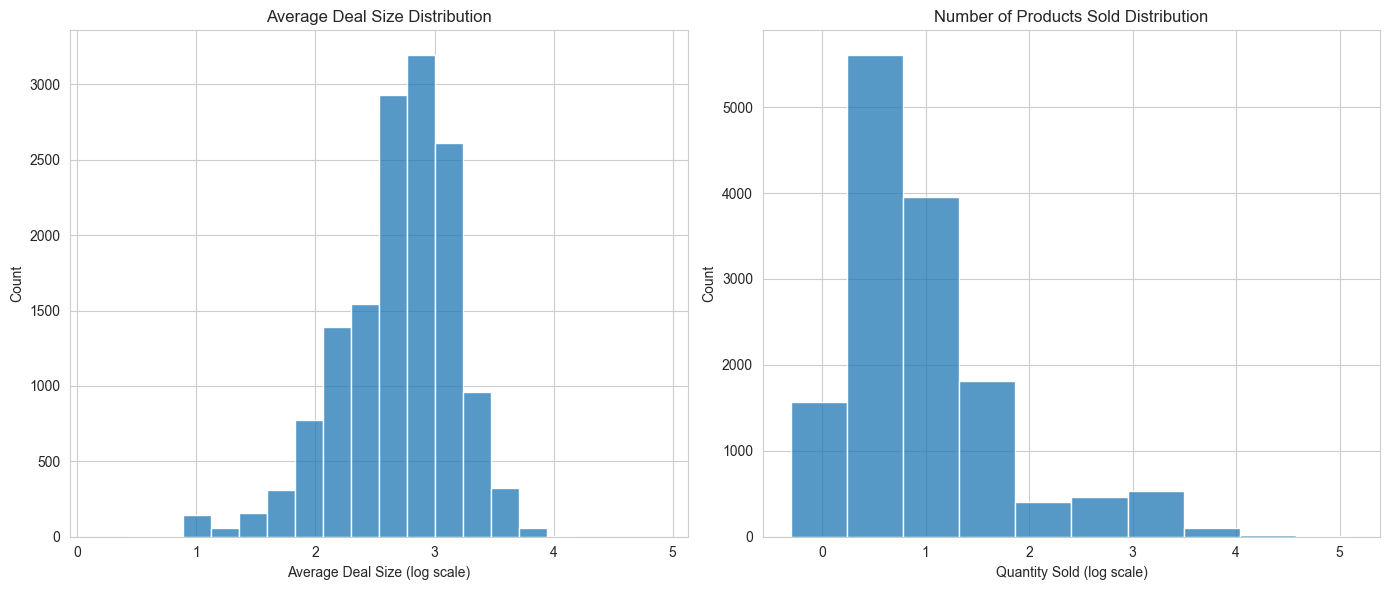

In [143]:
# plot log scale average deal size and number of deals distribution in two figures side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.histplot(np.log10(cusotmer_analysis['average_deal_size']), bins=20, ax=axes[0])
axes[0].set_title('Average Deal Size Distribution')
axes[0].set_xlabel('Average Deal Size (log scale)')
sns.histplot(np.log10(cusotmer_analysis['quantity_sold']), bins=10, ax=axes[1])
axes[1].set_title('Number of Products Sold Distribution')
axes[1].set_xlabel('Quantity Sold (log scale)')
plt.tight_layout()
plt.show()

Customer Characteristics Analysis

In the following customer characteristics analysis are carried out. Here are the findings:
* MediFoxStationary is the top performer among all business units
* Träger is the top category that delivers revenue
* As for the customer size (number of patients), those with zero and Unknow feature values deliver the most. However, this is not reliable as these values can be associated with missing data. The next best performers are customers with size between 101-500 

In [144]:
# Business unit performance
business_unit_summary = df.groupby('business_unit_account').agg(
    revenue=('totalprice', 'sum'),
    average_deal_size=('totalprice', 'mean'),
    quantity_sold=('quantity', 'sum'),  
    product_breadth=('product_id', 'nunique'),
).sort_values(by='revenue', ascending=False)
business_unit_summary

,revenue,average_deal_size,quantity_sold,product_breadth
business_unit_account,,,,
MediFoxStationary,"66,306,504.84","1,263.37","2,420,224.66",480
MediFoxAmbulant,"59,754,555.20",818.97,"301,283.95",1095
MediFoxTherapy,"6,447,692.49",512.17,"15,069.50",79
Jugendhilfe,"294,755.54",440.59,"2,849.00",58
Unknown,"66,725.00","1,551.74",160.75,12
IntegrationSupport,"24,607.23",683.53,338.00,34


In [145]:
# Category performance
category_summary = df.groupby('category').agg(
    revenue=('totalprice', 'sum'),
    average_deal_size=('totalprice', 'mean'),
    quantity_sold=('quantity', 'sum'),  
    product_breadth=('product_id', 'nunique'),
).sort_values(by='revenue', ascending=False)
category_summary

,revenue,average_deal_size,quantity_sold,product_breadth
category,,,,
Träger,"49,727,435.63","1,106.09","1,749,951.95",995
Trägerzugehöriger Mandant,"40,508,097.39",934.18,"633,585.66",1270
Einzelunternehmung,"39,487,944.03",843.35,"342,526.00",1133
Privater Betreiber,"2,541,624.23",951.56,"11,259.00",412
OrganisationBranch,"378,287.79",684.06,"1,189.00",89
Unknown,"251,451.23",603.00,"1,414.25",83


In [146]:
# Customer Size performance
customer_size_summary = df.groupby('size_category').agg(
    revenue=('totalprice', 'sum'),
    average_deal_size=('totalprice', 'mean'),
    quantity_sold=('quantity', 'sum'),  
    product_breadth=('product_id', 'nunique'),
).sort_values(by='revenue', ascending=False)
customer_size_summary

,revenue,average_deal_size,quantity_sold,product_breadth
size_category,,,,
0,"58,309,436.34",986.56,"1,707,500.41",1210
Unknown,"55,686,818.66","1,000.75","859,885.50",1190
101-500,"8,720,619.24",803.97,"79,070.50",557
51-100,"5,680,084.09",757.55,"45,136.25",527
11-50,"3,282,389.93",769.07,"33,637.00",456
10k+,"375,240.79","1,161.74","1,021.00",71
501-1k,"323,361.84",890.80,"2,626.20",118
1-10,"253,037.74",693.25,863.00,157
1k-5k,"198,237.75",702.97,"9,997.00",73


### 2. Product Analysis
**Question**: What are our top and bottom-performing products?

As before, revenue is chosen as primary, and the followings as secondary:
* Demand: total quantity sold (acquired by customers)
* Product Adoption Rate (PAR): the rate at which a product is acquired by customers

Below we see the 10 top and bottom-performing products. While the list of bottom-performing products seems normal, the top-performing list shows some inconsistent behavior. The first, 3rd and 4th products show significant PAR and high revenue, however, noticable low demand.  

In [147]:
total_accounts = df['account_id'].nunique()

product_analysis = df.groupby('product_id').agg(
    revenue=('totalprice', 'sum'),
    demand=('quantity', 'sum'),
    product_adoption_rate=('account_id', 'nunique')
).assign(product_adoption_rate=lambda x: x['product_adoption_rate'] / total_accounts * 100
).sort_values(by='revenue', ascending=False)
product_analysis.describe()

,revenue,demand,product_adoption_rate
count,"1,530.00","1,530.00","1,530.00"
mean,"86,859.37","1,790.80",0.47
std,"367,082.54","10,895.02",1.46
min,0.00,1.00,0.01
25%,"1,020.00",3.00,0.02
50%,"5,735.00",14.00,0.06
75%,"33,771.20",75.00,0.26
max,"7,329,724.56","130,275.00",18.11


In [148]:
product_analysis.nlargest(10, 'revenue')

,revenue,demand,product_adoption_rate
product_id,,,
4E379792F6CA656900028,"7,329,724.56","2,369.00",14.15
7BE3C12FFF792EAF3B6F0,"3,955,490.79","44,414.00",2.22
61233E9AA3DE0871EDE83,"3,880,456.05","2,597.00",17.88
3F4C583E435F9A8D587F7,"3,867,999.71","1,809.00",10.02
93F3B43B4843FD2D3A68C,"3,608,054.29","80,691.00",3.55
AD1608AD60EE303AD3E56,"3,480,924.01","49,769.00",2.45
F8084213096B16CBE3D36,"3,416,720.12","68,446.00",2.60
A3D5CC864369F8C0584B6,"2,639,151.08","88,638.00",3.13
8C124F2D9D17F4E4F780A,"2,500,412.48","82,381.00",2.63


In [149]:
product_analysis.nsmallest(10, 'revenue')

,revenue,demand,product_adoption_rate
product_id,,,
F68EC0F9ADB56999CD9CC,0.00,1.00,0.01
B53D3D31E7D12731D8A2B,1.80,1.00,0.01
0866439520B9BCAD66765,5.00,1.00,0.01
04BE9264E151F4062FD95,5.00,1.00,0.01
411005831003570512BC1,5.00,1.00,0.01
A6E945BF44B9F8991FD2A,5.00,1.00,0.01
94BE4B2CA6CBF126D7C82,6.00,1.00,0.01
B4244A9F8646A87BCCE25,6.90,1.00,0.01
5E65911BEC368ABA8132E,9.90,1.00,0.01


Product Category Analysis

Here, product categories are analyzed based on the same metrics as above, however, another important metric is added:
* Product Breadth: number of unique products in each category

We see that the product category one is the well deserved top performer. The anomoly in this is product category 9, with having ironicly offering only 9 products, but having large revenue and reletively large demand.

In [150]:
product_category_analysis = df.groupby('product_category').agg(
    revenue = ('totalprice', 'sum'),
    demand = ('quantity', 'sum'),
    product_adoption_rate = ('account_id', 'nunique'),
    product_breadth = ('product_id', 'nunique'),
    ).assign(product_adoption_rate=lambda x: x['product_adoption_rate'] / total_accounts * 100
).sort_values(by='revenue', ascending=False)
product_category_analysis

,revenue,demand,product_adoption_rate,product_breadth
product_category,,,,
1.00,"64,269,539.48","913,242.00",57.56,530
2.00,"16,501,982.17","1,361,403.00",48.22,381
9.00,"15,702,280.93","240,175.00",20.30,9
4.00,"13,960,446.82","26,527.50",38.25,186
6.00,"9,192,060.73","2,544.66",11.39,44
3.00,"8,084,358.79","25,119.00",35.23,233
7.00,"1,729,693.35","152,153.20",12.10,104
5.00,"1,511,248.89","7,075.00",26.29,30
8.00,"788,019.43","4,961.00",12.41,32


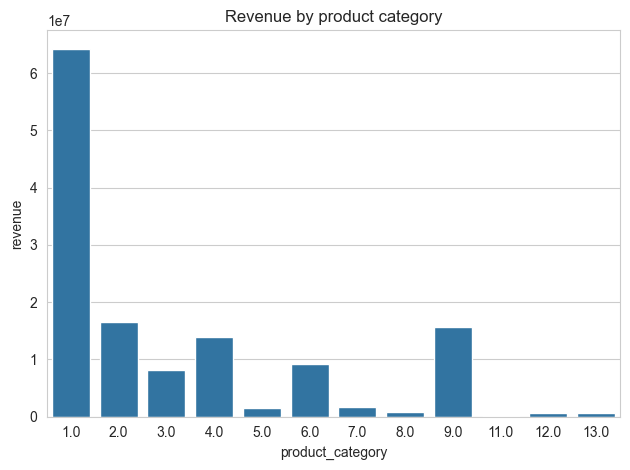

In [151]:
# For better and simpler understanding of relative comparison, the revenue is plotted below.
ax = sns.barplot(data=product_category_analysis, x='product_category', y='revenue')
ax.set_title('Revenue by product category')
plt.tight_layout()
plt.show()

Discount Analysis

To understand the effect of discount on demand, correlation analysis is carried out. The correlation between average discount and revenue is found to be 0.02. This shows that there is no significant correlation between discount and demand.

In [152]:
discount_demand_corr = df.discount.corr(df.quantity)
print(f"correlation between discount and demand: {discount_demand_corr.round(2)}")

correlation between discount and demand: 0.02


However, many cases are observed that unitprice is lower than the listprice. Assuming these are also discounts. I created new features. A preprocessing step is first applied, which is replacing zero listprice values with the average product list prices across data. 

In [153]:
# replace listprice wiht average unitprice per product whenever 0
df['listprice_new'] = df['listprice'].mask(
    df['listprice'] == 0,
    df.groupby('product_id')['unitprice'].transform('mean'))
# calculate new discount by unitprice/listprice_new
df['discount_new'] = df['discount'].mask(
    df['discount'] == 0,
    (1 - df['unitprice'] / df['listprice_new']) * 100)
# negative discount_new values should be set to 0 
# Assuming these are not discounts since unitprice > listprice for these cases
df['discount_new'] = df['discount_new'].mask(
    df['discount_new'] < 0, 0)

After this adjustment we see that there is evidance that demand increase slightly with increasign discount. 

In [154]:
discount_demand_corr = df.discount_new.corr(df.quantity)
print(f"correlation between discount and demand: {discount_demand_corr.round(2)}")

correlation between discount and demand: 0.21


Product Feature Analysis

Findings summary:
* Renewables have more revenue but lesser demand comapred to Fixed
* Compared to Fixed, renewables have almost 3 times higher unit/list-price and the unitprice is higher than the listprice
* not bundled products show significantly higher performance with 99% of the whole revenue
* When cosnidered together, not bundled and Renewables make up 72% of the revenue

In [155]:
# Subscription type performance
df.groupby('subscriptiontype').agg(total_revenue=('totalprice', 'sum'),
                                   demand =('quantity', 'sum'),
                                   unite_price=('unitprice', 'mean'),
                                   list_price=('listprice', 'mean'))

,total_revenue,demand,unite_price,list_price
subscriptiontype,,,,
Fixed,"34,016,041.88","1,685,481.00",182.91,192.33
Renewable,"98,878,798.42","1,054,444.86",624.31,576.58


In [156]:
# bundled products performance
df.groupby('bundled').agg(total_revenue=('totalprice', 'sum'),
                                demand =('quantity', 'sum'),
                                unite_price=('unitprice', 'mean'),
                                list_price=('listprice', 'mean'))

,total_revenue,demand,unite_price,list_price
bundled,,,,
False,"132,865,541.70","2,738,668.86",525.73,490.83
True,"29,298.60","1,257.00",75.00,58.53


In [157]:
pd.pivot_table(df,
               values='totalprice',
               columns='subscriptiontype',
               index='bundled',
               aggfunc='sum',
               )

subscriptiontype,Fixed,Renewable
bundled,,
False,"34,012,447.88","98,853,093.82"
True,"3,594.00","25,704.60"


Price Elasticity

To investigate price elasticity, we apply a simple regression analysis. The results show that the price is inelastic, such that a 1% increase in price will lead to a 0.3144 decreae in demand.

In [158]:
# average changes in quantity and price per product to estimate elasticity
elacticity = df[['quantity', 'unitprice', 'subscriptiontype', 'bundled']]
# log transform the variables cosnidering zero values
elacticity['log_quantity'] = np.log(elacticity['quantity'])
elacticity['log_unitprice'] = np.log(elacticity['unitprice'])
# subscriptiontype and bundled are controls
model = ols(formula='log_quantity ~ log_unitprice + C(subscriptiontype) + C(bundled)', data=elacticity).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           log_quantity   R-squared:                       0.462
Model:                            OLS   Adj. R-squared:                  0.462
Method:                 Least Squares   F-statistic:                 3.969e+04
Date:                Sat, 31 Jan 2026   Prob (F-statistic):               0.00
Time:                        09:02:58   Log-Likelihood:            -2.2937e+05
No. Observations:              138784   AIC:                         4.588e+05
Df Residuals:                  138780   BIC:                         4.588e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
====================================================================================================
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                            3.6106      0.008    450.512      0.000       3.595       3.626
C(subscriptiontype)[T.Renewable]    -1.4629      0.009   -164.218      0.000      -1.480      -1.445
C(bundled)[T.True]                  -0.6505      0.084     -7.780      0.000      -0.814      -0.487
log_unitprice                       -0.3144      0.002   -209.262      0.000      -0.317      -0.311
==============================================================================
Omnibus:                     8666.041   Durbin-Watson:                   2.003
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            11522.266
Skew:                           0.576   Prob(JB):                         0.00
Kurtosis:                       3.815   Cond. No.                         126.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### 3. Customer Structure Analysis
**Question**: What is our customer structure and what insights can we derive?

Customoer Business Unit Distribution

The following plots show the distribution of business unit representing sales and accounts. Most important insight is, while MediFoxAmbulant is a more active unit comapred to MediFoxStationary, the latter generates more revenue.


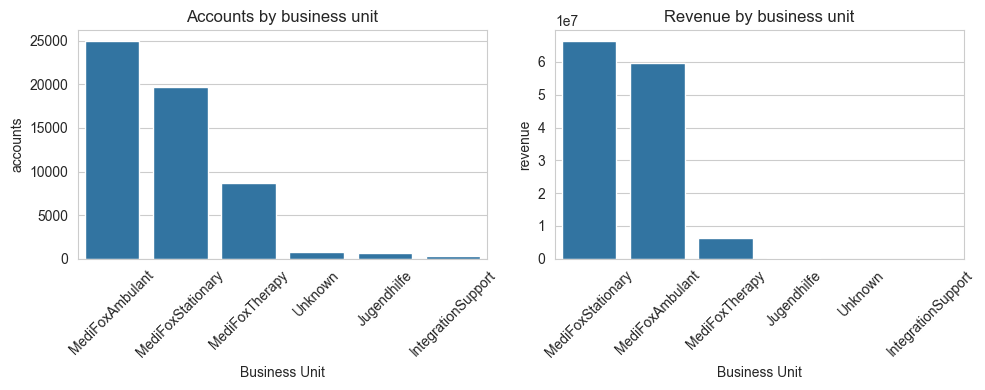

In [159]:
# Business Unit distribution
bu_accounts = accounts['business_unit'].value_counts().reset_index(name='accounts').rename(columns={'index': 'business_unit'})
bu_revenue = df.groupby('business_unit_account').agg(revenue = ('totalprice', 'sum')).reset_index().sort_values('revenue', ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(data=bu_accounts, x='business_unit', y='accounts', ax=axes[0])
axes[0].set_title('Accounts by business unit')
axes[0].set_xlabel('Business Unit')
axes[0].tick_params(axis='x', rotation=45)
sns.barplot(data=bu_revenue, x='business_unit_account', y='revenue', ax=axes[1])
axes[1].set_title('Revenue by business unit')
axes[1].set_xlabel('Business Unit')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

Parent Child Analysis

* As level of hierarchy increases, customers make less deals with MediFox leading to lower revenue
* The results show around 81 million is generated only from customers with no parent which is already 60% of the revenue

In [160]:
# self join acounts to establish parent child relationships in deeper levels
df_tmp = accounts[['id', 'parent_account']].copy()
for i in range(5):
    df_tmp = df_tmp.merge(
        accounts[['id', 'parent_account']],
        left_on='parent_account',
        right_on='id',
        how='left',
        suffixes=('', f'_lvl{i+1}')
    )
    df_tmp['parent_account'] = df_tmp[f'parent_account_lvl{i+1}']

df_tmp = df_tmp[['id', 
                'id_lvl1', 
                'id_lvl2', 
                'id_lvl3',
                'id_lvl4',
                'id_lvl5']]

# find how many parents are there for each account
df_tmp['parents_num'] = df_tmp[['id_lvl1', 'id_lvl2', 'id_lvl3', 'id_lvl4', 'id_lvl5']].notnull().sum(axis=1)
df['parents_num'] = df_tmp.set_index('id').loc[df['account_id'], 'parents_num'].values
# examining the levels performance
df.groupby('parents_num').agg(revenue=('totalprice', 'sum'),
                                average_deal_size=('totalprice', 'mean'),
                                quantity_sold=('quantity', 'sum'),  
                                product_breadth=('product_id', 'nunique'),
                                ).sort_values(by='revenue', ascending=False)

,revenue,average_deal_size,quantity_sold,product_breadth
parents_num,,,,
0,"81,645,064.16",966.00,"1,654,824.95",1290
1,"39,260,867.07",965.59,"905,760.08",1198
2,"9,623,494.90",891.48,"151,370.33",749
3,"1,988,363.19",836.85,"25,948.50",404
4,"347,745.48",893.95,"1,967.00",146
5,"29,305.50",651.23,55.00,36


Customer Size

A deeper analysis is shown above. The plots show additionally that size and revenue seem to move together.

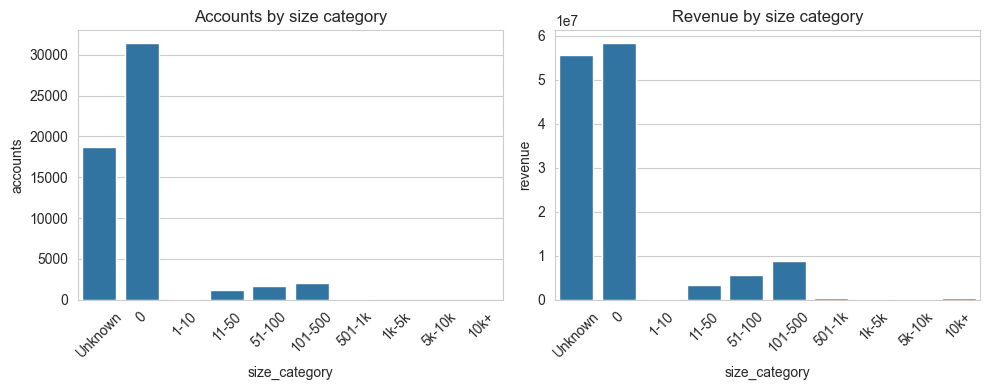

In [161]:
# Customer size analysis
size_accounts = accounts['size_category'].value_counts().reset_index(name='accounts').rename(columns={'index': 'size_category'})
size_revenue = df.groupby('size_category').agg(revenue = ('totalprice', 'sum')).reset_index().sort_values('revenue', ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(data=size_accounts, x='size_category', y='accounts', ax=axes[0])
axes[0].set_title('Accounts by size category')
axes[0].tick_params(axis='x', rotation=45)
sns.barplot(data=size_revenue, x='size_category', y='revenue', ax=axes[1])
axes[1].set_title('Revenue by size category')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

Lead Source

* Personal Contact is the most succussful lead source generating almost half of the total revenue
* Leagcy Lead comes next, with an exception that it leads to 3 times higher oppurtunities comapred to Personal Contact

In [162]:
# Lead source performance by revenue and quantity sold
lead_source_summary = df.groupby('lead_source').agg(revenue=('totalprice', 'sum'),
                                                    quantity_sold =('quantity', 'sum')
                                                  ).sort_values(by='revenue', ascending=False)
# oppurtunity counts for lead source
lead_source_counts = sales.groupby('lead_source').size().reset_index(name='opportunity_counts')
# merging results
lead_source_analysis = pd.concat([lead_source_summary, lead_source_counts.set_index('lead_source')], axis=1)
# considering only the 10 best lead sources
df_top_10_lead_sources = lead_source_analysis.nlargest(10, 'revenue')
df_top_10_lead_sources

,revenue,quantity_sold,opportunity_counts
lead_source,,,
Personal Contact,"63,038,110.69","1,747,292.83",10413
LegacyLead,"35,721,771.61","487,354.53",32012
Email,"12,601,594.47","218,848.00",5507
Call,"7,910,911.55","117,124.50",1871
WebsiteContactForm,"4,374,042.57","9,986.00",1851
Trade Show,"4,265,034.29","81,165.00",770
Other,"1,682,406.11","27,750.00",1524
WebsiteAppointmentForm,"743,990.65","14,087.00",212
Recommendation,"716,411.94","7,156.00",105


The following plot shows the distribution of lead sources in for each business unit. 
* Legacy Lead is more present in Therapy and less in Jugenhilfe
* In contrast, Personal Contact follows a complete opposite trend

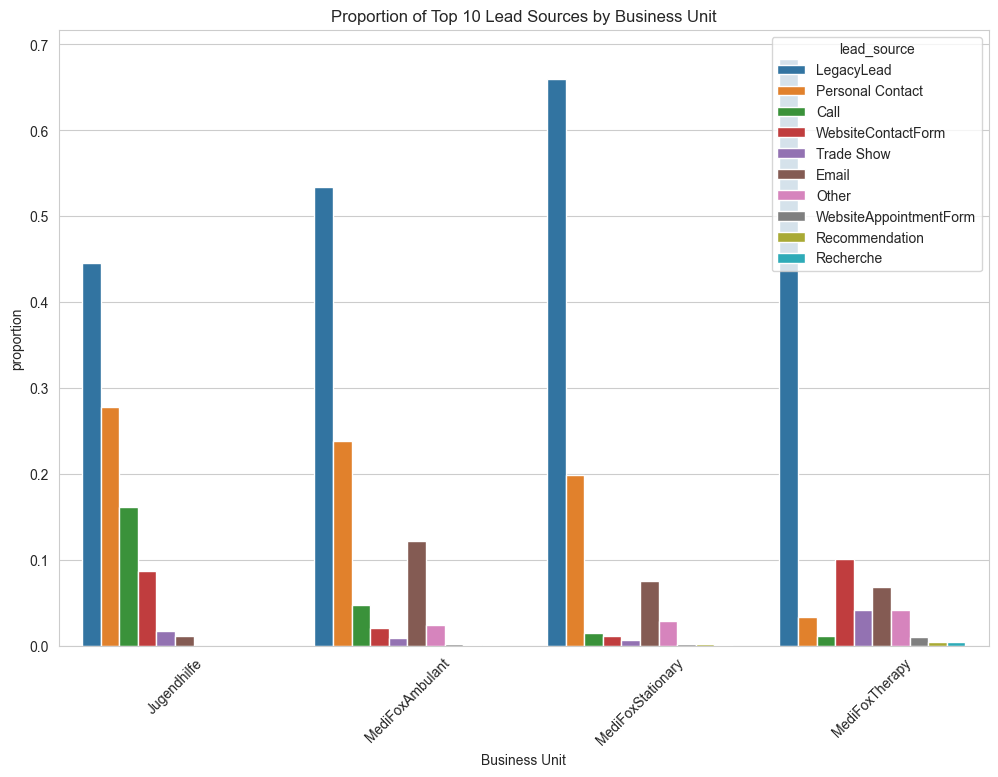

In [163]:
# extracting lead source names
top_10_lead_sources = df_top_10_lead_sources.index.tolist()
# finding only oppurtunities with top 10 lead sources
df_tmp_sales = sales[sales['lead_source'].isin(top_10_lead_sources)]
# grouping by bu
df_grp = df_tmp_sales.groupby('business_unit')['lead_source'].value_counts(normalize=True).reset_index(name='proportion')

# plotting proportions
plt.figure(figsize=(12, 8))
sns.barplot(data=df_grp, x='business_unit', y='proportion', hue='lead_source')
plt.title('Proportion of Top 10 Lead Sources by Business Unit')
plt.xlabel('Business Unit') 
plt.xticks(rotation=45)
plt.show()

Geographical Distribution

Below we see the number of accounts with different billing address, and those with at least 2customers having the same address. This probabaly has something to do with customer hierarchies. 

In [164]:
df_geo_analysis = accounts.billing_address.value_counts().reset_index()
# number of accounts having unique billing address
print(f"Number of accounts with different billing address: {df_geo_analysis.query('count == 1').shape[0]}")
non_unqiue_address = df_geo_analysis.query('count > 1')
print(f"Number of accounts with the same billing address: {non_unqiue_address.shape[0]}")
non_unqiue_address['count'].describe()

Number of accounts with different billing address: 34109
Number of accounts with the same billing address: 6885


count   6,885.00
mean        3.05
std         8.37
min         2.00
25%         2.00
50%         2.00
75%         3.00
max       463.00
Name: count, dtype: float64

### 4. Recommendation Engine
**Question**: Which products could be recommended to which customers based on similarities?

In the follwoing blocks, I build a hybrid, customer-based recommendation engine: 

Step 1. I engineered customer features by identifying the top 3 product categories by revenue for each business unit, size category, and industry category. In this way, I wanted to capture industry and segment purchasing patterns of products 

Step 2. A customer–product revenue matrix to represent current product ownership. I chose revenue since it represent both quantity and price.  


Step 3. Both behavior and feature data for fair comparison and learning. 

Step 4. Customer similarity is computed using cosine similarity on purchase behavior (what customers buy) and Euclidean distance on customer features (who customers are), and these are combined into a final similarity score using a weighting factor (alpha). 

Step 5. The recommendation algorithm uses this similarity matrix to find the most similar customers and recommends products they buy that the target customer does not.

This approach not only considers current products behavior but also customer purchasing beahvior. 

In [165]:
### In this block the customer feature matrix is built
# function to get top-3 product categories by revenue for a given feature
def top3_categories_by_feature(feature_col):
    top3 = (df.groupby([feature_col, 'product_category'])['totalprice']
              .sum()
              .reset_index()
              .sort_values([feature_col, 'totalprice'], ascending=[True, False])
              .groupby(feature_col)
              .head(3))
    
    top3['rank'] = top3.groupby(feature_col).cumcount() + 1
    return top3.pivot(index=feature_col, columns='rank', values='product_category')

# compute top-3 categories per feature value
bu_top3   = top3_categories_by_feature('business_unit_account')
size_top3 = top3_categories_by_feature('size_category')
cat_top3  = top3_categories_by_feature('category')

# map back to customers
customer_features = df[['account_id','business_unit_account','size_category','category']] \
    .drop_duplicates('account_id') \
    .set_index('account_id')

customer_features = customer_features.join(
    bu_top3, on='business_unit_account', rsuffix='_bu'
).join(
    size_top3, on='size_category', rsuffix='_size'
).join(
    cat_top3, on='category', rsuffix='_cat'
)

customer_features = customer_features.iloc[:,3:]
# rename columns clearly
customer_features.columns = [
    'bu_top1','bu_top2','bu_top3',
    'size_top1','size_top2','size_top3',
    'cat_top1','cat_top2','cat_top3'
]


In [166]:
# customer-product matrix repreenting total revenue per customer per product
customer_product = df.pivot_table(
    index='account_id',
    columns='product_id',
    values='totalprice',
    aggfunc='sum',
    fill_value=0
)

In [167]:
# scaling the matrices to get better results in similarity calculations
X_purchases_scaled = StandardScaler().fit_transform(customer_product)
X_features_scaled  = StandardScaler().fit_transform(customer_features)

###  similarity calculations
# customer product similarity calcualtion based on cosine similarity
sim_purchase = cosine_similarity(X_purchases_scaled)

# customer feature similarity calculation based on euclidean distance
dist_features = pairwise_distances(X_features_scaled, metric='euclidean')
sim_features = 1 / (1 + dist_features) 

# weight for behavior similarity
alpha = 0.5   

# final similarity matrix combining both purchase behavior and customer features
similarity_matrix = alpha * sim_purchase + (1 - alpha) * sim_features
similarity_df = pd.DataFrame(similarity_matrix,
                             index=customer_product.index,
                             columns=customer_product.index)



In [168]:
#  recommendation algothirm based on collaborative filtering
def recommend_products(customer_id, top_k=5, n_recs=3):
    # finding similar customers
    similar_customers = similarity_df[customer_id].sort_values(ascending=False)[1:top_k+1]
    # owmed products by the customer
    customer_products = customer_product.loc[customer_id]
    owned_products = customer_products[customer_products > 0].index
    # products of similar customers
    candidate_products = customer_product.loc[similar_customers.index]
    # get rid of products already owned
    candidate_products = candidate_products.drop(columns=owned_products, errors='ignore')
    # higher scores win
    scores = candidate_products.sum().sort_values(ascending=False)
    return scores.head(n_recs)

In [169]:
# sample recommendation
sample_customers = customer_product.index.to_series().sample(10, random_state=1818)
recommendations = {c: list(recommend_products(c, top_k=5, n_recs=5).items())
                   for c in sample_customers}
recommendations_df = pd.DataFrame(recommendations)
recommendations_df

,D737C19FB93C569C0DF9D,59F990DE9FF08DA437C13,C0AC534E9ECCDF09F85D6,1271FEF2AAFC1066F2778,EB7CC5E19A5102C0F55D5,D40E8F59C1A4CA3DCCD8D,BBDBA770BAD2E5724E23C,E75C26C72FDCB26D24D51,C28D7E81FD2F1FF3128FB,83B3D31D9F3C4A7EF2203
0,"(6718BBB85A5503253BD86, 4999.0)","(9602C84125FBD931D5EFB, 1700.0)","(18FD256C37D04D6CA4537, 3290.0)","(2E7DEFBA7B9C9AF2B580F, 9.9)","(4E379792F6CA656900028, 6990.0)","(93F3B43B4843FD2D3A68C, 28555.309999999998)","(4E379792F6CA656900028, 3490.0)","(224207B0B72859A7AA755, 4490.0)","(986D6313CF8783EB98E6F, 2619.0)","(AF9DC42C6B30DB5E490BD, 338.0)"
1,"(16D49DA0FCF3B74616B69, 2880.0)","(C4B41CE77629F39E5F678, 927.0)","(21C1A1E68C3C8A7A9D56F, 1695.0)","(04EFB0E419A45F81589C6, 0.0)","(AF9DC42C6B30DB5E490BD, 9.9)","(0683AEA1698A2B92327C6, 10203.75)","(C9C69C30CBCC4CFF01557, 545.0)","(4E379792F6CA656900028, 3990.0)","(033B9642316BAB4114A1B, 677.2)","(9DB3C124B8B579DDAE615, 87.0)"
2,"(EF0E1D97F4A65B2AB9818, 2496.0)","(60031E03BF7BFA045BC2B, 744.0)","(3EAD371C451CD477247A7, 1645.0)","(FD461B7ECB7CD8E29A310, 0.0)","(04DC54D279325C16869EA, 0.0)","(5A2EB5FFF6D29316E874B, 9380.0)","(FA84943D14BDE41A79343, 249.0)","(E3248A7971C462B51DFD0, 3990.0)","(FA84943D14BDE41A79343, 498.0)","(5C8FF6AE2FE64F635F608, 49.5)"
3,"(8CF1C6F6B3DB58C44FE21, 2400.0)","(87780B7506EA66A4DDBDB, 300.0)","(4DDB4718B2336327C6CE0, 1570.0)","(FD373CB5ED1C11A48DA88, 0.0)","(FD461B7ECB7CD8E29A310, 0.0)","(AD1608AD60EE303AD3E56, 6997.0)","(F040B36BF92B317279B33, 198.0)","(DAAA2079E84090171F58F, 1590.0)","(FCD46C3EC0D432BE82B39, 10.0)","(244DE4950964922A76FED, 39.6)"
4,"(A95E07B4A9237CA14ABCC, 1900.0)","(183162A6C33755CEE1905, 99.0)","(61233E9AA3DE0871EDE83, 1499.0)","(01AE3EF4B87E1D057F253, 0.0)","(FD373CB5ED1C11A48DA88, 0.0)","(7BE3C12FFF792EAF3B6F0, 6667.92)","(FCD46C3EC0D432BE82B39, 4.9)","(969A8286072A3F9D3AE52, 1323.0)","(FD461B7ECB7CD8E29A310, 0.0)","(4D08936AD98C52D248C82, 11.7)"


Validating Recommendations for cusotmer "D737C19FB93C569C0DF9D"

In [170]:
# recommended products not already owned
account = recommendations_df.columns[0]
recommended_products = recommendations_df[account].apply(lambda x: x[0]).to_list()
existing_products = df.query(f'account_id == "{account}"')['product_id']
pd.Series(recommended_products).isin(existing_products)

0    False
1    False
2    False
3    False
4    False
dtype: bool

### Executive Summary

This analysis examines customer behavior, product performance, and revenue drivers across different customer and product features to identify growth opportunities. Key findings include:

* MediFoxStationary and MediFoxAmbulant are the strongest business units, together generating approximately 95% of total revenue.

* The largest revenue contributions come from Träger (38%), Trägerzugehöriger (30%), and Mandant/Einzelunternehmung (29%) customer categories.

* Customer size could not be reliably analyzed due to a high level of missing data. This indicates a need for improving data collection.

* Product categories 1 and 2 dominate performance, generating the highest revenues; category 2 shows higher purchase frequency, while category 1 has broader customer adoption.

* Demand shows low sensitivity to discounts and is price inelastic. This suggest price reductions might not lead to significant demand gains.

* Lead source analysis indicates more reliance on traditional channels, with limited contribution from newer marketing approaches.

Finally, a recommendation engine was developed to identify relevant cross-sell opportunities for customers based on similarity patterns. This tool aims for targeted product suggestions. What it provides for business are: 
* More efficient sales prioritization 
* Generating more sales by increasing the likelihood of additional purchases by existing customers
* Consequently leading to lowering costs for acquiring new customers

### Bonus Question: Open Innovation Challenge

**Question**: Design and implement an additional data science use case that could provide business value using the available data.

#### Use case: Oppurtunity Conversion

Problem Definition
- **Business Context**: Not all oppurtunities lead to sales. As a sales consultant I am interested in knowing which opportunities lead to sales, hence, understanding conversion possibilities. In this way, sales team can focus on customers that are more likely to close a deal with. This is possible by investigating customer characteristics. 
- **Stakeholder Impact**: Improve in lead source management
- **Success Metrics**: Conversion rate, f1 score, auc score, accuracy
- **Business Value**: Increasing conversion of opportunities to sales

Methodology & Approach
- **Data Requirements**: accounts and sales datasets. Mainly, customer  characteristics features
- **Analytical Approach**: Supervised learning - Classification with opportunity conversion as target
- **Assumptions**: Same data preprocessing assumptions applies here

In [233]:
# merging accounts and sales
df_sales_accounts = sales.merge(accounts, 
                                left_on='account_id', 
                                right_on='id', 
                                how='inner', 
                                suffixes=('', '_account'))
# fidning opportunities that did not lead to sales, i.e., not in products dataset
opps = pd.Series(df_sales_accounts.id)
# find opps not in sales
not_converted = opps[~opps.isin(products.opportunity_id)]
converted = opps[opps.isin(products.opportunity_id)]
df_sales_accounts['converted'] = df_sales_accounts['id'].isin(converted).astype(int)
df_sales_accounts[['converted']].value_counts(normalize=True)


converted
1           0.61
0           0.39
Name: proportion, dtype: float64

In [234]:
# feature engineering for conversion prediction model
df_sales_accounts['opportunity_age_days'] = (df_sales_accounts['closedate'] - df_sales_accounts['opportunity_first_creation_date']).dt.days
df_model = df_sales_accounts.drop(columns=['id', 
                                            'id_account', 
                                            'account_id', 
                                            'closedate', 
                                            'opportunity_first_creation_date', 
                                            'billing_address', 
                                            'shipping_address',
                                            'parent_account',
                                            'klienten_bewohner',
                                            'renewal_model',
                                            'number_patients',
                                            'business_unit',
                                            'record_type_name'])
cat_cols = ['lead_source', 'category', 'business_unit_account']
df_model[cat_cols] = df_model[cat_cols].astype('category')


In [235]:
df_model.info()

<class 'pandas.DataFrame'>
RangeIndex: 55940 entries, 0 to 55939
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   lead_source            54900 non-null  category
 1   category               55940 non-null  category
 2   business_unit_account  55940 non-null  category
 3   size_category          55940 non-null  category
 4   converted              55940 non-null  int64   
 5   opportunity_age_days   55940 non-null  int64   
dtypes: category(4), int64(2)
memory usage: 1.1 MB


In [236]:
# train-test split
test_size = 0.4
rn_state = 777
y = df_model.pop('converted')
X_train, X_test, y_train, y_test = train_test_split(
    df_model, y, test_size=test_size, random_state=rn_state, stratify=y
) 
model = HistGradientBoostingClassifier(l2_regularization = 0.5, 
                                       min_samples_leaf = 20, 
                                       max_depth = 10, 
                                       learning_rate = 0.05)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(f"AUC-ROC Score: {round(roc_auc_score(y_pred, y_test), 2)}")
print(classification_report(y_pred, y_test))

AUC-ROC Score: 0.84
              precision    recall  f1-score   support

           0       0.71      0.84      0.77      7405
           1       0.91      0.83      0.87     14971

    accuracy                           0.84     22376
   macro avg       0.81      0.84      0.82     22376
weighted avg       0.85      0.84      0.84     22376



Further investigations to improve modeling results: 
* Better feature engineering 
* Grid search for better hyper parameter tuning
* Check for overfitting by comparing train and test results

Validation is carried our by applying monitoring to new cases that arise, i.e., oppurtunities that convert to sales. This is done by monitoring prediction quality, business KPIs if possible, model stability, and data drifts. But most importantely, sales team feedback and insights should be collected to improve model performance. 

The trained model will be deployed and used for generating predictions for new cases. A prediction for a new case oppurtunity gives the probabaility of the oppurtunity converting. These are shared with the sales team in CRM tools potentially. The sales team can use the predictions and combine them with their primary knowledge to improve their operations. 

